In [98]:
# ============================================
# MNIST DATASET - EXPLORATORY DATA ANALYSIS
# Name: Nandish C. Patil
# Branch: ECE
# Semester: 3rd Semester
# ============================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import warnings

warnings.filterwarnings("ignore")

# Plot settings
sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (9, 5)
plt.rcParams["font.size"] = 11

print("Libraries imported successfully!")

Libraries imported successfully!


In [99]:
# Load MNIST dataset

from tensorflow.keras.datasets import mnist

(X_train, y_train), (X_test, y_test) = mnist.load_data()

print("MNIST dataset loaded successfully!")
print("Training data shape:", X_train.shape)
print("Training labels shape:", y_train.shape)
print("Testing data shape:", X_test.shape)
print("Testing labels shape:", y_test.shape)

MNIST dataset loaded successfully!
Training data shape: (60000, 28, 28)
Training labels shape: (60000,)
Testing data shape: (10000, 28, 28)
Testing labels shape: (10000,)


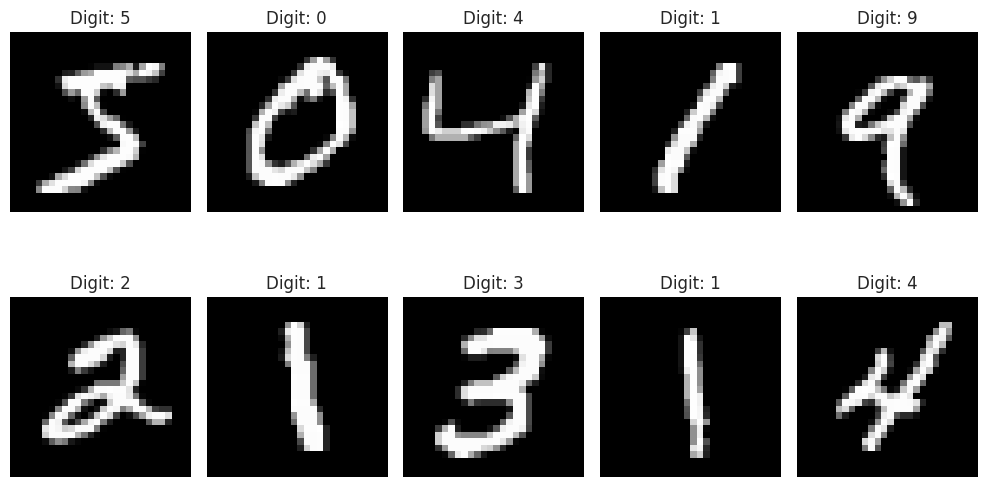

In [100]:
# Display sample MNIST images

plt.figure(figsize=(10, 6))

for i in range(10):
    plt.subplot(2, 5, i + 1)
    plt.imshow(X_train[i], cmap="gray")
    plt.title(f"Digit: {y_train[i]}")
    plt.axis("off")

plt.tight_layout()
plt.show()

Number of images for each digit:
0    5923
1    6742
2    5958
3    6131
4    5842
5    5421
6    5918
7    6265
8    5851
9    5949
Name: count, dtype: int64


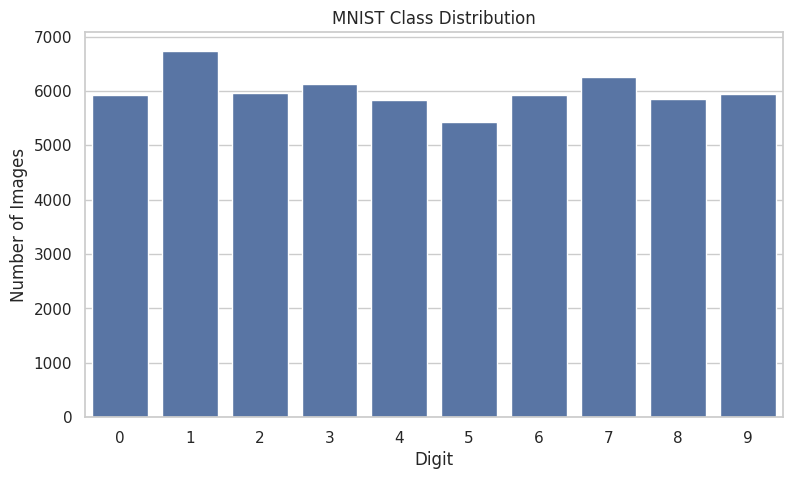

In [101]:
# Class distribution

class_counts = pd.Series(y_train).value_counts().sort_index()

print("Number of images for each digit:")
print(class_counts)

plt.figure(figsize=(9, 5))
sns.barplot(x=class_counts.index, y=class_counts.values)

plt.xlabel("Digit")
plt.ylabel("Number of Images")
plt.title("MNIST Class Distribution")

plt.show()

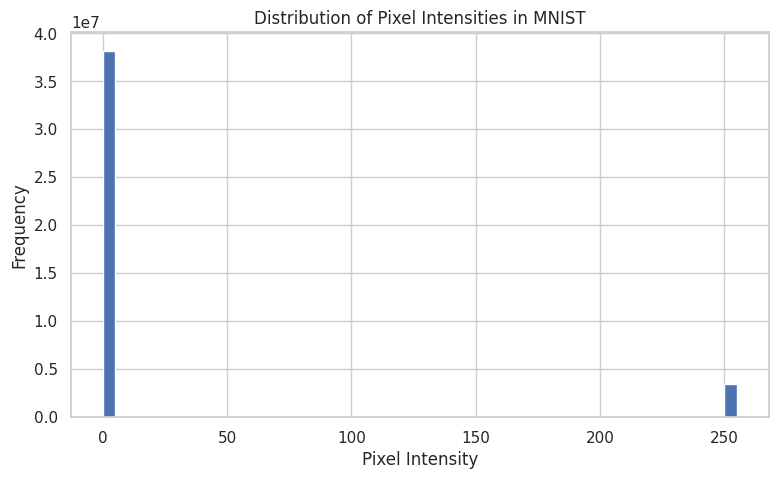

In [102]:
# Pixel intensity distribution

pixel_values = X_train.flatten()

plt.figure(figsize=(9, 5))
plt.hist(pixel_values, bins=50)

plt.xlabel("Pixel Intensity")
plt.ylabel("Frequency")
plt.title("Distribution of Pixel Intensities in MNIST")

plt.show()

In [103]:
# Check for missing values

print("Missing values in training images:", np.isnan(X_train).sum())
print("Missing values in testing images:", np.isnan(X_test).sum())

Missing values in training images: 0
Missing values in testing images: 0


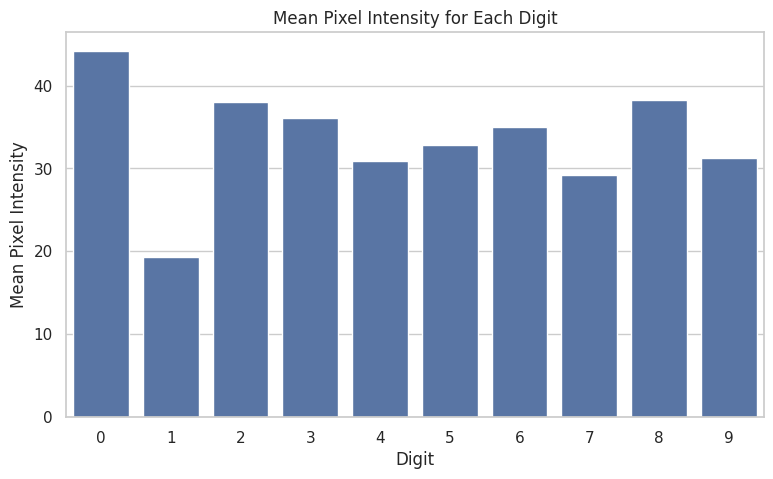

In [104]:
# Mean pixel intensity for each digit

mean_intensity = []

for digit in range(10):
    digit_images = X_train[y_train == digit]
    mean_value = digit_images.mean()
    mean_intensity.append(mean_value)

plt.figure(figsize=(9, 5))
sns.barplot(x=list(range(10)), y=mean_intensity)

plt.xlabel("Digit")
plt.ylabel("Mean Pixel Intensity")
plt.title("Mean Pixel Intensity for Each Digit")

plt.show()

     Digit 0    Digit 1
0  39.661990  21.855867
1  45.195153  22.507653
2  46.565051  13.869898
3  47.533163  14.823980
4  58.090561  21.144133


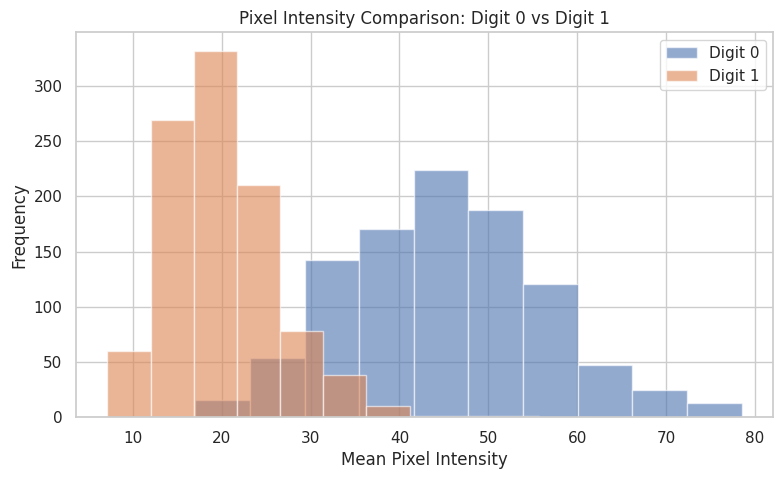

In [105]:
# Compare pixel intensity of digit 0 and digit 1

digit_0 = X_train[y_train == 0].mean(axis=(1, 2))
digit_1 = X_train[y_train == 1].mean(axis=(1, 2))

comparison_df = pd.DataFrame({
    "Digit 0": digit_0[:1000],
    "Digit 1": digit_1[:1000]
})

print(comparison_df.head())

plt.figure(figsize=(9, 5))

plt.hist(digit_0[:1000], alpha=0.6, label="Digit 0")
plt.hist(digit_1[:1000], alpha=0.6, label="Digit 1")

plt.xlabel("Mean Pixel Intensity")
plt.ylabel("Frequency")
plt.title("Pixel Intensity Comparison: Digit 0 vs Digit 1")
plt.legend()

plt.show()

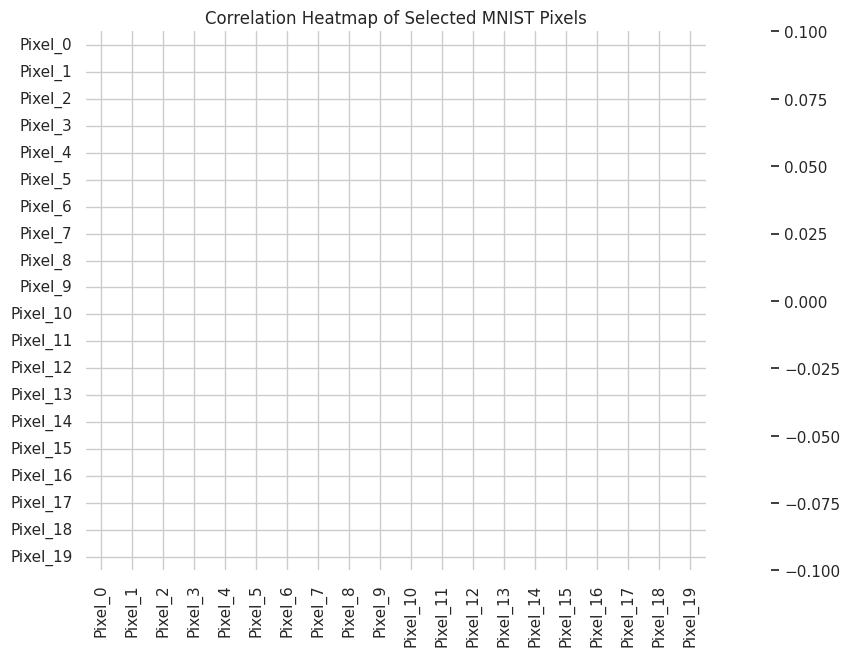

In [106]:
# Correlation heatmap using selected pixel features

sample_images = X_train[:500]
sample_flat = sample_images.reshape(500, -1)

# Select some pixels to make the correlation easier to visualize
selected_pixels = sample_flat[:, :20]

pixel_df = pd.DataFrame(
    selected_pixels,
    columns=[f"Pixel_{i}" for i in range(20)]
)

correlation = pixel_df.corr()

plt.figure(figsize=(10, 7))
sns.heatmap(correlation, cmap="coolwarm", center=0)

plt.title("Correlation Heatmap of Selected MNIST Pixels")
plt.show()

Objective
To perform Exploratory Data Analysis (EDA) on the MNIST handwritten digit dataset and understand its structure, pixel values, class distribution, and relationships between selected pixel features using Python.

Methodology
	1.	Load the MNIST dataset.
	2.	Import the required Python libraries such as NumPy, Pandas, Matplotlib and Seaborn.
	3.	Check the shape and structure of the dataset.
	4.	Examine the first few samples.
	5.	Analyze the distribution of handwritten digit classes.
	6.	Check for missing values and duplicate records.
	7.	Visualize sample MNIST images.
	8.	Analyze pixel intensity values.
	9.	Perform correlation analysis on selected pixel features.
	10.	Record the important observations from the EDA.

## Observations

1. The MNIST dataset contains handwritten digit images from 0 to 9.
2. Each image has a size of 28 × 28 pixels.
3. The pixel values range from 0 to 255.
4. The dataset contains 10 different classes representing digits 0 to 9.
5. The class distribution is approximately balanced.
6. No missing values were found in the dataset.
7. Pixel intensity analysis helps us understand the structure of handwritten digits.
8. Visualization makes it easier to identify patterns and differences between different digits.
9. Correlation analysis shows relationships between selected pixel features.
10. EDA helps us understand the dataset before applying machine-learning or deep-learning models.